# Science frame correction 

Before using them for science, *science frames* must be corrected for the two effects that we have seen in the previous lectures:

1) Removal of **bias** level, through the *median bias calibration frame*.
2) Correction for **pixel response non-uniformity**, through the *median normalized flat calibritation frame*.

Each step brings with it an associated error that we have to take into account, together with the *read-out noise* and the *photon noise* of the frame:


1) The error associated with the subtraction of the bias has to be summed in quadrature with the read-out noise.
2) The photon noise must be computed from the scientific frame **after** subtracting the bias, since *only* the photo-electrons (o.e., astrophysical signals) follow a Poisson distribution, and added in quadrature to the estimate of step one. 
3) Finally, you can apply the *flat correction* and propagate the associated error, using the error estimate of step 2 for the debiased frame. 

Remember the definition: a **Poisson distribution** (/ˈpwɑːsɒn/) is a discrete probability distribution that expresses the probability of a given number of events occurring in a fixed interval of time if these events occur with a known constant mean rate and independently of the time since the last event.

Let's call $\lambda$ the expected value of a Poisson random variable. For sufficiently large values of $\lambda$, the *normal distribution* with *mean* $\lambda$ and *variance* $\lambda$ (*standard deviation* $\sqrt {\lambda }$)  is an excellent approximation to the Poisson distribution.
Be sure to check **at least** the *Descriptive statistics*, *Assumptions and validity*, *Parameter estimation* on [Wikipedia](https://en.wikipedia.org/wiki/Poisson_distribution) \

**Important discalimer**\
During the course (and the exam), I will assume you know every aspect of the **normal distribution**, as it has already been introduced in many experimental physics and astronomy courses, usually during the Bachelor's degree. Incorrect answers regarding the normal distribution will result in failing the exams. 

## Testing the code on a subset of images

Before launching the Jupyter notebook, remember to 

1) Create the science list. 
2) Create a directory called `correct` inside your *dataset* directory 

We will also use the `jplephem` package. 
There is a shortcut to do it from inside the jupyter notebook:


In [1]:
import sys
!{sys.executable} -m pip install jplephem

  Using cached jplephem-2.24-py3-none-any.whl.metadata (24 kB)
Using cached jplephem-2.24-py3-none-any.whl (49 kB)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget
from astropy.io import fits 
import pickle 

It's time to load the science file list:

In [9]:
science_list = np.genfromtxt('./group00_GJ3470_20220328/science/science.list',dtype=str)
print('Number of scientific images: {0:5.0f}'.format(len(science_list)))

Number of scientific images:  1996



We will test our reduction pipeline and tools to extract aperture photometry only on a small subsample of images. \
Reducing and saving all the images will take more space than the computer has available. 
In this example, I will use only ten images.
**Note:** Check that the interval of your choice is within the total lenght of the `science_list`. If not, the size of the subset will be zero

In [10]:
science_test_list = science_list[1100:1110] 
print('Number of selected scientific images: {0:5.0f} (must be > 0)'.format(len(science_test_list)))

Number of selected scientific images:    10 (must be > 0)


## Data reduction steps

Science data reduction includes these steps:
1) multiplication by gain
2) bias subtraction
3) division by flat 

These components contribute to the error budget:
- readout noise
- error associated with the bias
- error associated with the flat
- photon noise (target + sky background)



We load the median bias and the median normalized flat (with its error) \
We must use the same bias error and readout noise estimates we used for the flat correction. 

In [11]:
median_bias = pickle.load(open("group00_GJ3470_20220328/median_bias.p", "rb"))
median_bias_error =  pickle.load(open("group00_GJ3470_20220328/median_bias_error.p", "rb"))
median_normalized_flat =  pickle.load(open("group00_GJ3470_20220328/median_normalized_flat.p", "rb"))
median_normalized_flat_errors =  pickle.load(open("group00_GJ3470_20220328/median_normalized_flat_errors.p", "rb"))

For the photon noise, we can rely on Poissonian distribution as done with the flat.
Remember that the photon noise must be computed *after* removing the bias but *before* correcting for the flat field, as the error must be calculated on the actual number of photons received on the detector, not on the predicted photons we would measure with a perfectly manufactured CCD.


In [13]:
for science_name in science_test_list:
    science_fits = fits.open('./group00_GJ3470_20220328/science/' + science_name)
    
    readout_noise = science_fits[0].header['RDNOISE'] # [e] photoelectrons
    gain = science_fits[0].header['GAIN']  # [e/ADU]
    
    science_data = science_fits[0].data * gain # save the data from the first HDU 
    science_fits.close()

    science_debiased = science_data - median_bias
    science_corrected = science_debiased / median_normalized_flat

    ## Error associated to the science corrected frame
    science_debiased_errors = np.sqrt(readout_noise**2 + median_bias_error**2 + science_debiased)
    science_corrected_errors = science_corrected * np.sqrt((science_debiased_errors/science_debiased)**2 + (median_normalized_flat_errors/median_normalized_flat)**2)


/tmp/ipykernel_4781/620805474.py:11: RuntimeWarning: divide by zero encountered in divide
  science_corrected = science_debiased / median_normalized_flat
/tmp/ipykernel_4781/620805474.py:11: RuntimeWarning: invalid value encountered in divide
  science_corrected = science_debiased / median_normalized_flat
/tmp/ipykernel_4781/620805474.py:15: RuntimeWarning: divide by zero encountered in divide
  science_corrected_errors = science_corrected * np.sqrt((science_debiased_errors/science_debiased)**2 + (median_normalized_flat_errors/median_normalized_flat)**2)
/tmp/ipykernel_4781/620805474.py:15: RuntimeWarning: invalid value encountered in multiply
  science_corrected_errors = science_corrected * np.sqrt((science_debiased_errors/science_debiased)**2 + (median_normalized_flat_errors/median_normalized_flat)**2)


Do not worry if you run into this warning, as it is likely due to the presence of zero values in the overscan region of the flat: \
`RuntimeWarning: divide by zero encountered in divide`

Remember the difference between a *warning* and an *error*: 
- **warning**: Something has not worked as it should. The code keeps running, but you should investigate the source of the warning and decide whether it is relevant or can be ignored.
- **error**: Something *serious* has gone wrong and the code stopped running

For now, we keep the warnings, but we may want to suppress them when running the analysis over thousands of images. The official Python documentation helps us. 
[temporarily suppressing warnings](https://docs.python.org/3/library/warnings.html#temporarily-suppressing-warnings) and 
[completely suppressing the warnings](https://docs.python.org/3/library/warnings.html#overriding-the-default-filter)

## Saving the images 

We now repeat the same steps again, but this time, we save the output into a file. \
First of all, from the terminal let's make a directory where to store the new files. \
```bash
mkdir correct
```
Be sure to be in the same folder where you launched the Jupyter Notebbok.

We want to use the same file names for our new frames, without the  `.fits` extension. The extension is 5 characters long; i.e., we can take the string identifying each file name and remove the last 5 characters. In Python notation:
```python
science_name[:-5]
```
The new file name is made by adding new string characters at the beginning and at the end of the original name:

```python
new_name = './correct/' + science_name[:-5] + '_corr.p'
```

In [14]:
print(science_name)
print(science_name[:-5])
new_name = science_name[:-5] + '_corr.p'
print(new_name)

AF771843.fits
AF771843
AF771843_corr.p


In [15]:
for science_name in science_test_list:
    science_fits = fits.open('./group00_GJ3470_20220328/science/' + science_name)

    readout_noise = science_fits[0].header['RDNOISE'] # [e] photoelectrons
    gain = science_fits[0].header['GAIN']  # [e/ADU]

    science_data = science_fits[0].data * gain # save the data from the first HDU 
    science_fits.close()
    
    science_debiased = science_data - median_bias
    science_corrected = science_debiased / median_normalized_flat

    ## Error associated to the science corrected frame
    science_debiased_errors = np.sqrt(readout_noise**2 + median_bias_error**2 + science_debiased)
    science_corrected_errors = science_corrected * np.sqrt((science_debiased_errors/science_debiased)**2 + (median_normalized_flat_errors/median_normalized_flat)**2)

    new_name = './group00_GJ3470_20220328/correct/' + science_name[:-5] + '_corr.p'
    pickle.dump(science_corrected, open(new_name, 'wb'))
    new_name = './group00_GJ3470_20220328/correct/' + science_name[:-5] + '_corr_errors.p'
    pickle.dump(science_corrected_errors, open(new_name, 'wb'))
    


/tmp/ipykernel_4781/1764993495.py:11: RuntimeWarning: divide by zero encountered in divide
  science_corrected = science_debiased / median_normalized_flat
/tmp/ipykernel_4781/1764993495.py:11: RuntimeWarning: invalid value encountered in divide
  science_corrected = science_debiased / median_normalized_flat
/tmp/ipykernel_4781/1764993495.py:15: RuntimeWarning: divide by zero encountered in divide
  science_corrected_errors = science_corrected * np.sqrt((science_debiased_errors/science_debiased)**2 + (median_normalized_flat_errors/median_normalized_flat)**2)
/tmp/ipykernel_4781/1764993495.py:15: RuntimeWarning: invalid value encountered in multiply
  science_corrected_errors = science_corrected * np.sqrt((science_debiased_errors/science_debiased)**2 + (median_normalized_flat_errors/median_normalized_flat)**2)


## Extracting and saving useful information

**Question**: When did we gather our observations?\
Epochs of astronomical observations are expressed in [Julian Days JD](https://en.wikipedia.org/wiki/Julian_day), usually in the [Coordinated Universal Time UTC](https://en.wikipedia.org/wiki/Coordinated_Universal_Time) scale, unless differently specified in the instrument documentation.\
To convert the Julian Day into the standard format used in everyday life, you can use any online converter [like this one](https://www.aavso.org/jd-calculator)

We can retrieve the JD of our observations directly from the header of the fits file, and convert it using the [`astropy.time` package](https://docs.astropy.org/en/stable/time/index.html)

To get the JD:
```python
bias00_time = bias00_hdu.header['JD']
print('Julian date       : {0:12.6f} JD'.format(bias00_time))
```

We create a `time` object following the `astropy.time` documentation:
```python
from astropy.time import Time
t = Time(bias00_hdu.header['JD'], format='jd', scale='utc')`
```
where:
- the `format` argument specifies how to interpret the input values (e.g., ISO, JD, or Unix time).
- the `scale` argument specifies the time scale for the values (e.g., UTC, TT, or UT1).
Finally, we print the date following the [ISO representation](https://en.wikipedia.org/wiki/ISO_8601):

```python
print('ISO representation: {0:s}'.format(t.iso))`
```

The difference between different time scales will be discussed in another later.

For our analysis, we need to know **when** the data were collected, not just how. In addition, we may need some additional information regarding the telescope's pointing.
- The epoch at the beginning of the exposure, expressed in Julian date
- The exposure time, i.e., the duration of our exposure
- The airmass of the telescope at the beginning the exposure

We extract this information from the header of each FITS file.
Other info you may need, e.g., the filter used for the observations, does not change with time, so you just need to extract them from a single frame. 


In [16]:
n_images = len(science_test_list)

array_jd = np.zeros(n_images)
array_exptime = np.zeros(n_images)
array_airmass = np.zeros(n_images)


for i_science, science_name in enumerate(science_test_list):

    science_fits = fits.open('./group00_GJ3470_20220328/science/'+science_name)    
    array_jd[i_science] = science_fits[0].header['JD']
    array_exptime[i_science] = science_fits[0].header['EXPTIME']
    array_airmass[i_science] = science_fits[0].header['AIRMASS']

    ## Let's print the comment for the first image
    if i_science==0:
        print('{0:12.4f} :  {1:s}, scale {2:s}'.format(array_jd[i_science], science_fits[0].header.comments['JD'], science_fits[0].header['TIMESYS']))
        print('{0:12.1f} :  {1:s}'.format(array_exptime[i_science], science_fits[0].header.comments['EXPTIME']))
        print('{0:12.2f} :  {1:s}'.format(array_airmass[i_science], science_fits[0].header.comments['AIRMASS']))
        print('{0:12.4f} :  {1:s}'.format(science_fits[0].header['SITELONG'], science_fits[0].header.comments['SITELONG']))
        print('{0:12.4f} :  {1:s}'.format(science_fits[0].header['SITELAT'], science_fits[0].header.comments['SITELAT']))    
        print('{0:12.4f} :  {1:s}'.format(science_fits[0].header['SITEELEV'], science_fits[0].header.comments['SITEELEV']))    
        print('{0:12s} :  {1:s}'.format(science_fits[0].header['OBJCTRA'], science_fits[0].header.comments['OBJCTRA']))    
        print('{0:12s} :  {1:s}'.format(science_fits[0].header['OBJCTDEC'], science_fits[0].header.comments['OBJCTDEC']))    
    
        telescope_longitude = science_fits[0].header['SITELONG']
        telescope_latitude = science_fits[0].header['SITELAT']
        telescope_elevation = science_fits[0].header['SITEELEV']
        object_ra = science_fits[0].header['OBJCTRA']
        object_dec = science_fits[0].header['OBJCTDEC']
        #print(science_fits[0].header)
    science_fits.close()

2459667.3534 :  JD at start, scale UTC
         5.0 :  [s] Exposure time
        1.25 :  Telescope airmass at start
     11.5690 :  [deg] Telescope longitude, E11:34:08.397
     45.8486 :  [deg] Telescope latitude, N45:50:54.894
   1376.2000 :  [m] Telescope height above sea level
07:59:05.56  :  Object RA (J2000.0)
+15:23:27    :  Object DEC (J2000.0)


## Conversion to a time standard independent from the location of the observer. 

Did you notice that the Julian Date is expressed as JD and not BJD, i.e., *Barycentric Julian Date*?
JD is the time when an event is recorded at the observatory. What we want, in reality, is the time recorded at the Barycenter of the Solar System, as we do not want to be influenced by the specific position of the observatory when observations are taken.

Check the story of how the Danish astronomer Ole Roemer (1644–1710) became the first person to measure the speed of light in 1676, to see how the position of the observer may influence your results.

The correction is done through several steps:
1) We want each time stamp to be associated with the centre of the exposure, not the initial moment. We have to shift all the time stamps by half the exposure time
2)  We have to shift from [Coordinated Universal Time (UTC)](https://en.wikipedia.org/wiki/Coordinated_Universal_Time) (a discontinuous scale due to the introduction of leap seconds) to the [Barycentric Dynamical Time (TDB)](https://en.wikipedia.org/wiki/Barycentric_Dynamical_Time), a relativistic coordinate time scale defined on the barycenter of the Solar system.
3)  We have to correct for the *light travel time* effect, i.e.,  the time required by the light to travel between Earth (specifically, our observatory) and the Solar System barycenter, i.e., [Barycentric Julian Date (BJD)](https://en.wikipedia.org/wiki/Barycentric_Julian_Date)

The final results will convert **JD_UTC** to **BJD_TDB**

We rely on the `Time` package of `Astropy` to perform all these calculations. Check [the documentation](https://docs.astropy.org/en/stable/time/) for more examples.
We also need to specify an Astronomical Coordinate System for our target as required by the Astropy package. For this purpose, we rely on the [`coordinates`](https://docs.astropy.org/en/stable/coordinates/index.html) package.

In [20]:
from astropy import coordinates as coord, units as u
from astropy.time import Time, TimeDelta


In [21]:
observatory = coord.EarthLocation.from_geodetic(
    lon=telescope_longitude * u.deg,
    lat=telescope_latitude * u.deg,
    height=telescope_elevation * u.m)

In [22]:
# SIMBAD / Gaia EDR3, ICRS coordinates  at the epoch J2000
target_j2000 = coord.SkyCoord(
    '07:59:05.8395356736', '+15:23:29.236065000',
    unit=(u.hourangle, u.deg), frame='icrs', obstime=Time('J2000'),
    pm_ra_cosdec=-185.706*u.mas/u.yr, pm_dec=-56.994*u.mas/u.yr,
    distance=(34.0172*u.mas).to(u.pc, equivalencies=u.parallax()),
    radial_velocity=26.341*u.km/u.s)

We have to account for the space motion of our target between J2000 and the epoch of our observations. We use the method [`apply_space_motion`](https://docs.astropy.org/en/stable/coordinates/apply_space_motion.html) using the epoch of the first observation as reference. We assume that the movement of an object outside the Solar System is negligible over a few hours.

In [25]:
reference_epoch = Time(array_jd[0], format='jd', scale='utc', location=observatory)
target = target_j2000.apply_space_motion(new_obstime=reference_epoch)

Let's make a plot of the light travel time correction along one year, for our target:

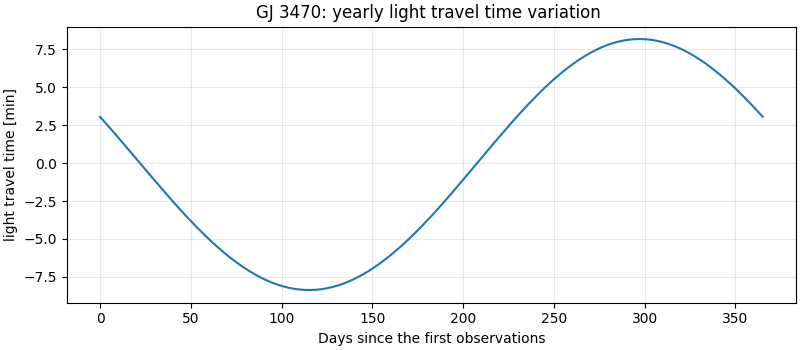

In [26]:
#https://docs.astropy.org/en/stable/time/

# let's compute the light travel time for one year of observations 
jd_plot = np.arange(np.floor(array_jd[0]), np.floor(array_jd[0]) + 365.25, 0.25)
tm_plot = Time(jd_plot, format='jd', scale='utc', location=observatory)
ltt_plot = tm_plot.light_travel_time(target, kind='barycentric')
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(jd_plot - jd_plot[0], ltt_plot.to_value(u.min))
ax.set(xlabel='Days since the first observations',
       ylabel='light travel time [min]', title='GJ 3470: yearly light travel time variation ')
ax.grid(alpha=0.3)
plt.show()


The [`light_travel_time`](https://docs.astropy.org/en/stable/api/astropy.time.Time.html#astropy.time.Time.light_travel_time) method will return a `TimeDelta` object already in TDB scale (including relativistic corrections), while the scale conversion from UTC to TDB for our array in JD UTC is done with the `tdb` method.

From the documentation of `light_travel_time`:

The routine assumes the source(s) are at a large distance, i.e., neglects finite-distance effects.

**Returns**: *time_offset* TimeDelta \
The time offset between the barycentre or Heliocentre and Earth, in TDB seconds. Should be added to the original time to get the time in the Solar System barycentre or the Heliocentre. Also, the time conversion to BJD will then include the relativistic correction as well.

Below, we compute the JD_UTC at mid exposure before converting to BJD_TDB

In [27]:
jd = array_jd + array_exptime/86400./2. 

tm_start = Time(array_jd, format='jd', scale='utc', location=observatory)
tm = tm_start + TimeDelta(array_exptime / 2, format='sec')

#Light travel time correction to the barycentre or heliocentre.
ltt_bary = tm.light_travel_time(target, kind='barycentric')

bjd_tdb = tm.tdb + ltt_bary

## Identification of the target and reference stars
Open a scientific frame and display it in order to identify the target star (the one with the transiting planet) and the reference stars (used to do differential photometry). You will need to use [SIMBAD](https://simbad.cds.unistra.fr/simbad/) for a correct identification. \
You can play with the `vmin` and `vmax` value to highlight fainter stars. 

vmin:  439.3    vmax: 31345.1


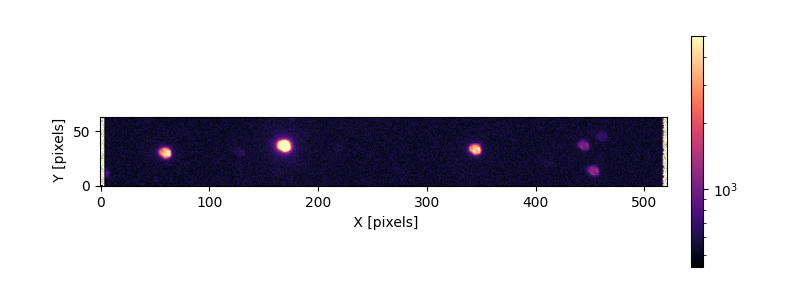

In [28]:
science_frame_name = './group00_GJ3470_20220328/correct/' + science_test_list[0][:-5] + '_corr.p'
science_corrected =    pickle.load(open(science_frame_name, 'rb'))

import matplotlib.colors as colors

vmin = np.amin(science_corrected[:,15:-15])
vmax = np.amax(science_corrected[:,15:-15])
print('vmin:  {0:.1f}    vmax: {1:.1f}'.format(vmin, vmax))

# Adjust the vmax value to highlight faint stars in the field
vmax = 5000

fig, ax = plt.subplots(1, figsize=(8,3))
im1 = plt.imshow(science_corrected, cmap=plt.colormaps['magma'], norm=colors.LogNorm(vmin=vmin, vmax=vmax), origin='lower')
plt.colorbar(im1,ax=ax, fraction=0.046, pad=0.04)
plt.xlabel(' X [pixels]')
plt.ylabel(' Y [pixels]')
plt.show()

You can get an approximate location by rolling the mouse over the star and taking note of the numbers displayed in the lower part of the frame. These are the values that I got:

In [29]:
x_target = 345
y_target = 33

x_reference_01 = 170
y_reference_01 = 38

You don't need to be extremely precise in defining the centres at this stage. We can get a better refinement by drawing a circle around each star. To speed up the process, I wrapped the plotting routines inside a function:

In [33]:
def make_circle_around_star(x_pos, y_pos, radius, thickness, color, alpha, label):

    # n = 50: the number of points used to approximate each circumference.
    # radii = [radius, radius+thickness]: the inner and outer radii of the annulus
    n, radii = 50, [radius, radius+thickness]

    # range for angular coordinate to draw the circle
    theta = np.linspace(0, 2*np.pi, n, endpoint=True)

    # outer product between two vectors. 
    # given a with size M and b with sixe N, the outcome c = np.outer(a, b) will have size MxN 
    # https://numpy.org/doc/1.26/reference/generated/numpy.outer.html
    xs = np.outer(radii, np.cos(theta))
    ys = np.outer(radii, np.sin(theta))

    # The slicing expression:
    # xs[1,::-1]
    #  means:
    #    1: select the second row, corresponding to the outer circumference.
    #    ::-1: reverse the order of its elements.
    # Consequently:
    # - The inner circumference is traversed counterclockwise.
    # - The outer circumference is traversed clockwise.
    # This is a trick used to make an empty circle surrouned by a corona

    xs[1,:] = xs[1,::-1]
    ys[1,:] = ys[1,::-1]

    # numpy.ravel returns a contiguous flatten array
    # https://numpy.org/doc/1.26/reference/generated/numpy.ravel.html
    # matplotlib.pyplot.fill will fill the area enclosed by a curve 
    ax.fill(np.ravel(xs)+x_pos, np.ravel(ys)+y_pos, edgecolor=None, facecolor=color, alpha=alpha, label=label)


Thanks to the function, you can draw as many circles as you want by simply adding one line of code. Below, I ran the script several times, changing slightly the position of the circles every time, until they were well centered around the star (Note: integer values are fine)

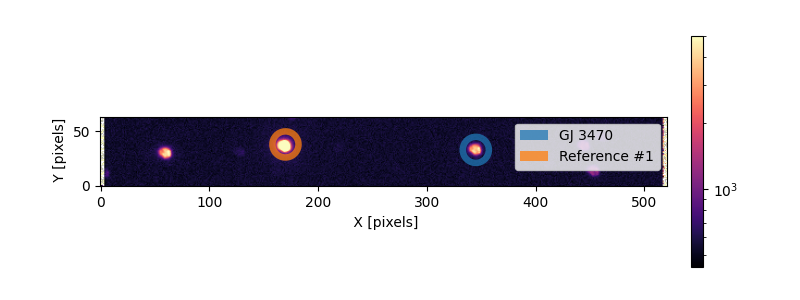

In [34]:
x_target = 345
y_target = 33

x_reference_01 = 170
y_reference_01 = 38

fig, ax = plt.subplots(1, figsize=(8,3))
im1 = plt.imshow(science_corrected, cmap=plt.colormaps['magma'], norm=colors.LogNorm(vmin=vmin, vmax=vmax), origin='lower')
plt.colorbar(im1,ax=ax, fraction=0.046, pad=0.04)

make_circle_around_star(x_target, y_target, radius=9, thickness=6, alpha=0.75, label='GJ 3470', color='C0')
make_circle_around_star(x_reference_01, y_reference_01, radius=9, thickness=6, alpha=0.75, label='Reference #1', color='C1')
plt.xlabel(' X [pixels]')
plt.ylabel(' Y [pixels]')
ax.legend()
plt.show()